# Smart Beta and Factor Investing

FINM 36700 HW6: Smart-Beta

Group: Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

## Setup

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

pd.options.display.float_format = "{:.4f}".format
ANN = 12
FILE = "factor_pricing_data.xlsx"

factors = pd.read_excel(FILE, sheet_name="factors (excess returns)", index_col=0, parse_dates=True)
ports   = pd.read_excel(FILE, sheet_name="portfolios (excess returns)", index_col=0, parse_dates=True)
ports.columns = ports.columns.str.strip()     # industry names are padded with spaces in the file

print(f"Factors: {list(factors.columns)}")
print(f"{ports.shape[1]} industry portfolios, {factors.index[0]:%Y-%m} to {factors.index[-1]:%Y-%m} ({len(factors)} months)")

Factors: ['MKT', 'SMB', 'HML', 'RMW', 'CMA', 'UMD']
49 industry portfolios, 1980-01 to 2025-04 (544 months)


---
# 2. The Factors

Data: `factor_pricing_data.xlsx`: monthly excess returns for MKT and five additional factors.

## 2.1
Analyze the factors (as with the Fama-French factors in Homework 4). Compare univariate statistics:
- mean
- volatility
- Sharpe

In [2]:
def summary(df):
    T = len(df)
    m, s = df.mean(), df.std()
    return pd.DataFrame({
        "Mean":     m * ANN,
        "Vol":      s * np.sqrt(ANN),
        "Sharpe":   m / s * np.sqrt(ANN),
        "t(mean)":  m / (s / np.sqrt(T)),
        "Skewness": df.skew(),
        "Min":      df.min(),
    })

SFMT = {"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}", "t(mean)": "{:.2f}",
        "Skewness": "{:.2f}", "Min": "{:.1%}"}

stats_full = summary(factors)
stats_full.style.format(SFMT)

,Mean,Vol,Sharpe,t(mean),Skewness,Min
MKT,8.49%,15.64%,0.54,3.66,-0.65,-23.2%
SMB,0.54%,10.14%,0.05,0.36,0.37,-15.5%
HML,2.65%,10.89%,0.24,1.64,0.14,-13.8%
RMW,4.51%,8.31%,0.54,3.66,-0.41,-18.9%
CMA,2.77%,7.25%,0.38,2.57,0.33,-7.1%
UMD,6.18%,15.35%,0.40,2.71,-1.35,-34.3%


**Answer:**

Over 1980–2025 every factor has a positive average excess return, but the six differ a lot:

- **Highest Sharpe ratios:** RMW (0.54) and MKT (0.54) are essentially tied. RMW gets there with half the market's volatility (8.3% vs 15.6%), so its smaller mean (4.5%) is very reliable (t ≈ 3.7).
- **Middle:** UMD (0.40) has a high mean (6.2%) but market-like volatility and the worst single month of any factor. CMA (0.38) has a modest mean but the lowest volatility (7.3%).
- **Weak:** HML (0.24) and especially SMB (0.05). The size premium is about 0.5% a year and statistically indistinguishable from zero (t ≈ 0.4). HML's t-stat (≈1.6) is also below the usual significance threshold.

Volatility matters as much as the mean here. The "new" factors (RMW, CMA) look unimpressive by their means but are among the best by Sharpe ratio.

## 2.2
Based on the factor statistics above:
- Does each factor have a positive risk premium (positive expected excess return)?
- How have the factors performed since the time of the case (2015-present)?

In [3]:
compare = pd.concat({"1980–2014": summary(factors.loc[:"2014"])[["Mean", "Vol", "Sharpe"]],
                     "2015–present": summary(factors.loc["2015":])[["Mean", "Vol", "Sharpe"]]}, axis=1)
compare.style.format("{:.2%}").format("{:.2f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "Sharpe"]])

Point estimates over ~10 years are noisy, so I add 95% confidence intervals for the mean. I also run a direct test of whether the post-2015 mean is *different* from the pre-2015 mean (Welch two-sample t-test).

In [4]:
def mean_ci(df, alpha=0.05):
    T = len(df)
    m, se = df.mean() * ANN, df.std() / np.sqrt(T) * ANN
    q = stats.t.ppf(1 - alpha / 2, T - 1)
    return pd.DataFrame({"Mean": m, "CI low": m - q * se, "CI high": m + q * se})

pre, post = factors.loc[:"2014"], factors.loc["2015":]
diff_test = pd.DataFrame({"Δ mean (post − pre)": (post.mean() - pre.mean()) * ANN,
                          "p-value": stats.ttest_ind(post, pre, equal_var=False).pvalue},
                         index=factors.columns)

ci_tbl = pd.concat({"Full sample": mean_ci(factors), "2015–present": mean_ci(post)}, axis=1).join(
    pd.concat({"Break test": diff_test}, axis=1))
ci_tbl.style.format("{:.2%}").format("{:.2f}", subset=[("Break test", "p-value")])

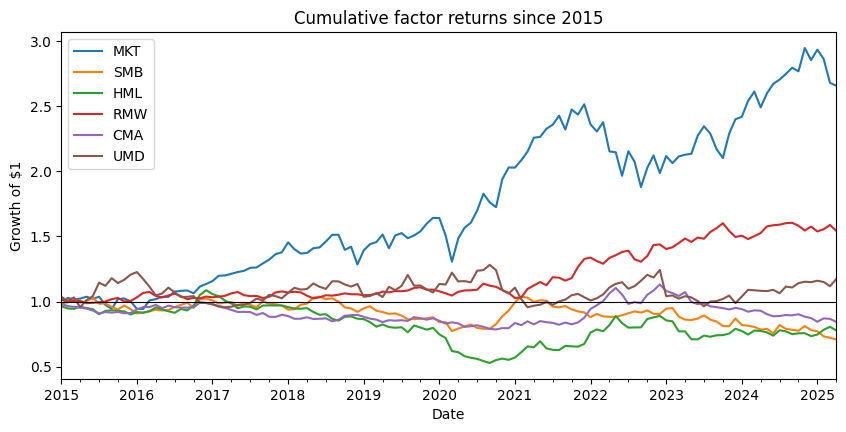

In [5]:
ax = (1 + factors.loc["2015":]).cumprod().plot(figsize=(10, 4.5), title="Cumulative factor returns since 2015")
ax.axhline(1, color="black", lw=0.8)
ax.set_ylabel("Growth of $1")
plt.show()

**Answer:**

*Positive premium?* Over the full sample, yes for all six. But only MKT, RMW, CMA and UMD have means that are statistically different from zero. The 95% intervals for SMB and HML include zero, so the data cannot confirm that they have a positive premium.

*Since the case (2015–present):* performance has split into two groups.
- **Kept working:** MKT (Sharpe 0.68, up from 0.50) and RMW (0.61, up from 0.53). UMD stayed positive but weakened a lot (mean 2.5%, down from 7.3%).
- **Stopped working:** SMB, HML and CMA all had *negative* average returns. Value has been the most discussed case, with a long drawdown into 2020 driven by growth/tech outperformance.

The statistics don't support a strong conclusion either way. All post-2015 confidence intervals for SMB, HML, CMA and UMD include zero, and the break tests do not reject equality of the pre- and post-2015 means at 5% for any factor. Ten years of monthly data with 10–14% volatility is too little to tell "the premium disappeared" apart from "a bad decade." Still, an investor buying smart-beta value or size products around 2015 would have been disappointed.

## 2.3
Report the correlation matrix across the six factors.
- Does the construction method succeed in keeping correlations small?
- Fama and French say HML is somewhat redundant in their 5-factor model. Does this seem to be the case?

In [6]:
corr = factors.corr()
corr.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,MKT,SMB,HML,RMW,CMA,UMD
MKT,1.00,0.23,-0.21,-0.25,-0.35,-0.18
SMB,0.23,1.00,-0.03,-0.41,-0.05,-0.06
HML,-0.21,-0.03,1.00,0.22,0.68,-0.21
RMW,-0.25,-0.41,0.22,1.00,0.14,0.07
CMA,-0.35,-0.05,0.68,0.14,1.00,0.00
UMD,-0.18,-0.06,-0.21,0.07,0.00,1.00


To test redundancy formally: if HML is redundant given the other four FF5 factors, a regression of HML on MKT, SMB, RMW and CMA should have an intercept of zero. In other words, a mix of the other factors replicates HML's average return.

In [7]:
def spanning(y, xcols):
    fit = sm.OLS(factors[y], sm.add_constant(factors[xcols])).fit()
    out = pd.DataFrame({"coef": fit.params, "t-stat": fit.tvalues})
    out.loc["const", "coef"] *= ANN
    out.loc["R²"] = [fit.rsquared, np.nan]
    return out

ff5_others = ["MKT", "SMB", "RMW", "CMA"]
spanning("HML", ff5_others).style.format("{:.3f}", na_rep="")

,coef,t-stat
const,-0.016,-1.289
MKT,0.042,1.778
SMB,0.069,1.878
RMW,0.218,4.825
CMA,1.025,20.633
R²,0.487,


For comparison, the same spanning regression for each of the other FF5 factors, using the remaining four as regressors. A factor is "redundant" if its alpha is insignificant.

In [8]:
ff5 = ["MKT", "SMB", "HML", "RMW", "CMA"]
span_all = {}
for f in ff5:
    fit = sm.OLS(factors[f], sm.add_constant(factors[[g for g in ff5 if g != f]])).fit()
    span_all[f] = {"alpha (ann.)": fit.params["const"] * ANN, "t(alpha)": fit.tvalues["const"], "R²": fit.rsquared}
pd.DataFrame(span_all).T.style.format({"alpha (ann.)": "{:.2%}", "t(alpha)": "{:.2f}", "R²": "{:.2f}"})

,alpha (ann.),t(alpha),R²
MKT,11.65%,5.44,0.19
SMB,1.75%,1.23,0.19
HML,-1.57%,-1.29,0.49
RMW,5.17%,4.64,0.23
CMA,2.80%,3.59,0.51


**Answer:**

*Small correlations?* Mostly yes. The long-short, size-neutral construction keeps most pairwise correlations at or below about 0.35 in absolute value, and several are close to zero (UMD–CMA 0.00, SMB–HML −0.03, SMB–CMA −0.05). There are two notable exceptions, and both have an economic explanation:
- **HML–CMA = 0.68.** Value firms (high book-to-market) tend to be low-investment firms, so both factors go long many of the same stocks.
- **SMB–RMW = −0.41.** Small firms tend to be less profitable, so the small leg of SMB looks like the weak leg of RMW.

*Is HML redundant?* Yes, and the spanning regression confirms it. Regressing HML on the other four FF5 factors gives an alpha of −1.6% a year (t ≈ −1.3, insignificant) with an R² of about 0.49, nearly all of it through CMA (loading ≈ 1.0, t ≈ 21). A combination of CMA and RMW reproduces HML's average return, so HML adds nothing to the mean-variance frontier of the other four. HML is the only one of the five whose spanning alpha is negative. RMW, CMA and MKT all have significant spanning alphas, and SMB's is positive but insignificant.

## 2.4
Report the tangency weights for a portfolio of these 6 factors.
- Which factors seem most important? And least?
- Are the factors with low mean returns still useful?
- Re-do the tangency portfolio with only MKT, SMB, HML, UMD. Which factors get high/low tangency weights now?

What do you conclude about the importance or unimportance of these styles?

In [9]:
def tangency(df):
    w = np.linalg.solve(df.cov(), df.mean())
    return pd.Series(w / w.sum(), index=df.columns)

def port_stats(df, w):
    r = df @ w
    return pd.Series({"Mean": r.mean() * ANN, "Vol": r.std() * np.sqrt(ANN),
                      "Sharpe": r.mean() / r.std() * np.sqrt(ANN)})

sets = {"6 factors": factors, "4 factors (MKT, SMB, HML, UMD)": factors[["MKT", "SMB", "HML", "UMD"]]}
w   = {k: tangency(v) for k, v in sets.items()}
tan = pd.concat([pd.DataFrame(w), pd.DataFrame({k: port_stats(sets[k], w[k]) for k in sets})])

tan.style.format("{:.1%}", na_rep="—").format("{:.2f}", subset=pd.IndexSlice[["Sharpe"], :])

,6 factors,"4 factors (MKT, SMB, HML, UMD)"
CMA,31.7%,—
HML,-2.0%,36.8%
MKT,21.6%,37.1%
RMW,30.6%,—
SMB,6.7%,-5.4%
UMD,11.4%,31.4%
Mean,4.8%,6.0%
Vol,4.0%,6.7%
Sharpe,1.19,0.91


Tangency weights depend on scale and leverage, so a clearer measure of each factor's importance is how much the maximum Sharpe ratio **falls when that factor is removed**:

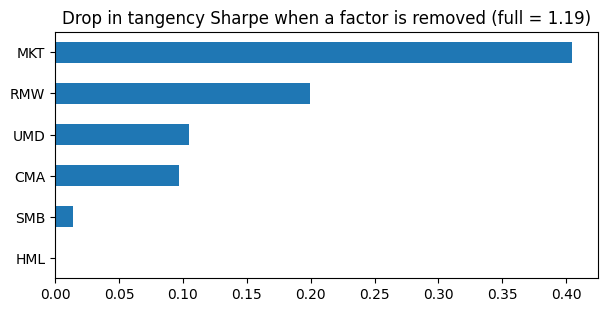

MKT   0.4040
RMW   0.1990
UMD   0.1050
CMA   0.0970
SMB   0.0140
HML   0.0010
Name: Sharpe lost if dropped, dtype: float64

In [10]:
full_sr = port_stats(factors, w["6 factors"])["Sharpe"]
drop_one = pd.Series({f: full_sr - port_stats(factors.drop(columns=f), tangency(factors.drop(columns=f)))["Sharpe"]
                      for f in factors.columns}, name="Sharpe lost if dropped").sort_values(ascending=False)

ax = drop_one.plot.barh(figsize=(7, 3.2), color="tab:blue",
                        title=f"Drop in tangency Sharpe when a factor is removed (full = {full_sr:.2f})")
ax.invert_yaxis()
plt.show()
drop_one.round(3)

**Answer:**

*6-factor tangency (Sharpe ≈ 1.19).* The largest weights go to **CMA (≈32%), RMW (≈31%) and MKT (≈22%)**, together about 84%. UMD gets ≈11%, SMB ≈7%, and **HML gets slightly negative weight (≈ −2%)**. The drop-one analysis ranks importance the same way. Removing MKT costs about 0.40 of Sharpe and RMW about 0.20. CMA and UMD each cost about 0.10. Removing SMB costs very little (0.01), and removing HML costs essentially nothing (0.001), consistent with the spanning result in 2.3.

*Are low-mean factors useful?* Yes. CMA has only a 2.8% mean but gets the largest weight, because it has low volatility and is negatively correlated with MKT (−0.35). The optimizer rewards what a factor adds to the *portfolio* (its mean relative to its covariance with everything else), not its stand-alone Sharpe ratio. The reverse also holds: HML has a positive mean, but it adds nothing once CMA is in the set.

*4-factor tangency (Sharpe ≈ 0.91).* Without RMW and CMA, the weights shift to **MKT (≈37%), HML (≈37%) and UMD (≈31%)**, and SMB is slightly negative (≈ −5%). HML jumps from −2% to 37% because, with CMA gone, it is the best available proxy for the investment/value exposure. UMD also gets more weight because it hedges HML (correlation −0.21). Losing RMW and CMA lowers the achievable Sharpe from 1.19 to 0.91.

*Conclusion.* A style's importance depends on which other styles are in the set:
- **MKT** is important in every set.
- **SMB** is unimportant in every set: its premium is small, and the other factors already capture its risk.
- **HML** is important only when CMA is absent. Value and investment are largely the same bet.
- **Profitability (RMW)** and **momentum (UMD)** add value that the classic FF3 factors don't have. This supports AQR's choice of "value, momentum, quality" as its core styles.

---
# 3. Testing Modern LPMs

Models:
- **CAPM**: MKT
- **FF3**: MKT, SMB, HML
- **FF5**: MKT, SMB, HML, RMW, CMA
- **AQR**: MKT, HML, RMW, UMD

Time-series test (AQR example):

$$\tilde{r}^i_t = \alpha^i + \beta^{i,\mathrm{MKT}} \tilde{f}^{\mathrm{MKT}}_t + \beta^{i,\mathrm{HML}} \tilde{f}^{\mathrm{HML}}_t + \beta^{i,\mathrm{RMW}} \tilde{f}^{\mathrm{RMW}}_t + \beta^{i,\mathrm{UMD}} \tilde{f}^{\mathrm{UMD}}_t + \varepsilon_t$$

Data: monthly excess returns on $n=49$ industry portfolios. Risk-free rate not needed.

I estimate all 49 regressions at once with matrix OLS ($B = (X'X)^{-1}X'Y$). This is equivalent to running them one by one, but it also gives the residual covariance matrix needed for the GRS joint test of $H_0: \alpha_1 = \dots = \alpha_n = 0$.

$$\text{GRS} = \frac{T-N-K}{N}\cdot\frac{\hat\alpha'\hat\Sigma_\varepsilon^{-1}\hat\alpha}{1+\bar f'\hat\Omega_f^{-1}\bar f} \sim F_{N,\,T-N-K}$$

In [11]:
models = {
    "CAPM": ["MKT"],
    "FF3":  ["MKT", "SMB", "HML"],
    "FF5":  ["MKT", "SMB", "HML", "RMW", "CMA"],
    "AQR":  ["MKT", "HML", "RMW", "UMD"],
}

def ts_test(cols, Y=ports):
    "Time-series regressions of every asset on the factors in `cols`, plus the GRS test."
    F = factors[cols]
    X = np.column_stack([np.ones(len(F)), F.values])
    T, N, K = len(Y), Y.shape[1], len(cols)

    B, *_ = np.linalg.lstsq(X, Y.values, rcond=None)          # (K+1) x N
    resid = Y.values - X @ B
    sigma_e = resid.T @ resid / (T - K - 1)                     # N x N residual covariance
    se = np.sqrt(np.outer(np.diag(np.linalg.inv(X.T @ X)), np.diag(sigma_e)))

    alpha = B[0]
    r2 = 1 - resid.var(axis=0) / Y.values.var(axis=0)

    fbar, omega = F.mean().values, F.cov().values
    grs = (T - N - K) / N * (alpha @ np.linalg.solve(sigma_e, alpha)) / (1 + fbar @ np.linalg.solve(omega, fbar))

    table = pd.DataFrame({"alpha": alpha * ANN, "t(alpha)": alpha / se[0], "R2": r2}, index=Y.columns)
    table[[f"beta_{c}" for c in cols]] = B[1:].T
    return table, {"GRS": grs, "GRS p-value": stats.f.sf(grs, N, T - N - K)}

## 3.1
Test the AQR 4-factor model using time-series regressions. For each regression, report the estimated $\alpha$ and $R^2$.

In [12]:
ts_aqr, grs_aqr = ts_test(models["AQR"])
ts_aqr[["alpha", "t(alpha)", "R2"]].style.format({"alpha": "{:.2%}", "t(alpha)": "{:.2f}", "R2": "{:.2f}"}) \
    .map(lambda t: "color: #c0392b; font-weight: bold" if abs(t) > 1.96 else "", subset=["t(alpha)"])

,alpha,t(alpha),R2
Agric,1.10%,0.40,0.34
Food,0.42%,0.24,0.46
Soda,1.82%,0.64,0.30
Beer,1.11%,0.55,0.42
Smoke,4.30%,1.44,0.27
Toys,-3.46%,-1.28,0.51
Fun,4.13%,1.59,0.61
Books,-3.54%,-1.97,0.69
Hshld,-1.02%,-0.64,0.56
Clths,-2.29%,-1.05,0.62


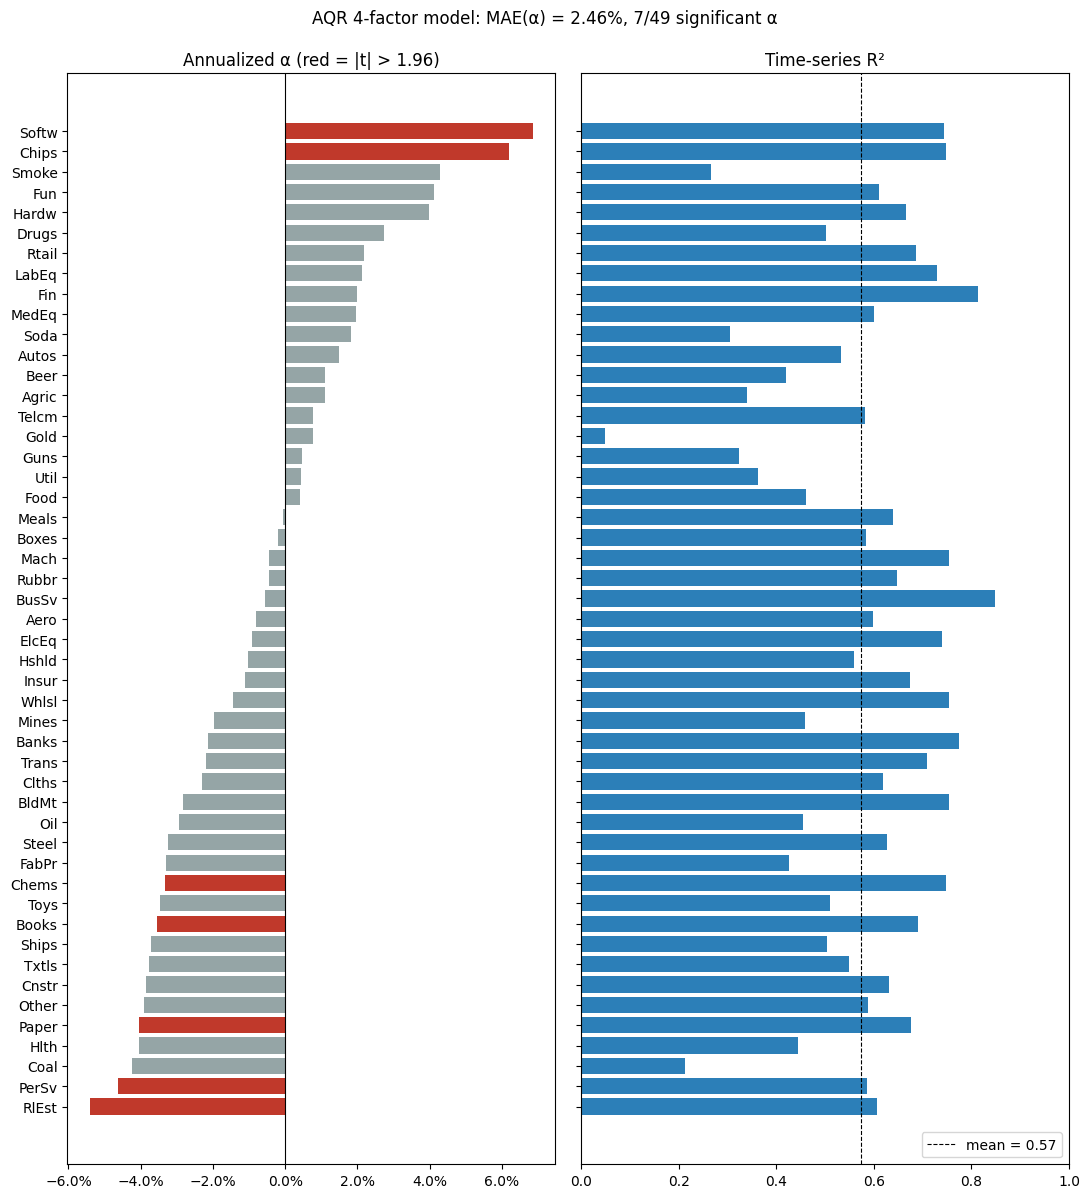

In [13]:
def plot_ts(ts, title):
    d = ts.sort_values("alpha")
    sig = d["t(alpha)"].abs() > 1.96
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 12), sharey=True)
    ax1.barh(d.index, d["alpha"], color=np.where(sig, "#c0392b", "#95a5a6"))
    ax1.axvline(0, color="black", lw=0.8)
    ax1.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax1.set_title("Annualized α (red = |t| > 1.96)")
    ax2.barh(d.index, d["R2"], color="#2c7fb8")
    ax2.axvline(d["R2"].mean(), color="black", ls="--", lw=0.8, label=f"mean = {d['R2'].mean():.2f}")
    ax2.set_xlim(0, 1)
    ax2.set_title("Time-series R²")
    ax2.legend(loc="lower right")
    fig.suptitle(f"{title}: MAE(α) = {d['alpha'].abs().mean():.2%}, {sig.sum()}/{len(d)} significant α", y=0.995)
    fig.tight_layout()
    plt.show()

plot_ts(ts_aqr, "AQR 4-factor model")

## 3.2
Calculate the mean absolute error of the estimated alphas:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n|\tilde{\alpha}^i|$$

- If the pricing model worked, should these alpha estimates be large or small? Why?
- Based on your MAE, does this support the pricing model or not?

In [14]:
mae_aqr = ts_aqr["alpha"].abs().mean()
print(f"AQR MAE(α)         = {mae_aqr:.2%} per year")
print(f"# |t(α)| > 1.96    = {(ts_aqr['t(alpha)'].abs() > 1.96).sum()} of {len(ts_aqr)} (≈{0.05*len(ts_aqr):.1f} expected by chance)")
print(f"GRS = {grs_aqr['GRS']:.2f}, p-value = {grs_aqr['GRS p-value']:.4f}")

AQR MAE(α)         = 2.46% per year
# |t(α)| > 1.96    = 7 of 49 (≈2.5 expected by chance)
GRS = 1.45, p-value = 0.0297


**Answer:**

If the model were correct, all alphas would be **zero** (small and statistically insignificant in a finite sample). A correct LFP says $E[\tilde r^i] = \beta^{i\prime}\,E[\tilde f]$, so each asset's average excess return is fully explained by its factor loadings times the factor premia. Any alpha is return the factors fail to explain, i.e. a pricing error.

The AQR model's MAE is about **2.5% a year**. That is large in economic terms, roughly 30% of the market premium (8.5%) and over a quarter of the average industry's excess return (≈8.9%). Seven of 49 alphas are significant, compared with about 2.5 expected by chance, led by Softw and Chips (positive) and RlEst, PerSv and Paper (negative).

The GRS test checks all 49 alphas jointly and takes into account that industry residuals are correlated. It **rejects** the AQR model at the 5% level (p ≈ 0.03). So the evidence does not support the AQR model as a complete pricing model for industry portfolios.

## 3.3
Test the CAPM, FF3 and FF5.
- Report the MAE for each and compare with the AQR MAE.
- Which model fits best?

In [15]:
ts_results, grs_results = {}, {}
for name, cols in models.items():
    ts_results[name], grs_results[name] = ts_test(cols)

fit_tbl = pd.DataFrame({
    m: {"# factors": len(models[m]),
        "MAE(α)": ts_results[m]["alpha"].abs().mean(),
        "# |t(α)|>1.96": (ts_results[m]["t(alpha)"].abs() > 1.96).sum(),
        **grs_results[m]}
    for m in models}).T
fit_tbl.style.format({"# factors": "{:.0f}", "MAE(α)": "{:.2%}", "# |t(α)|>1.96": "{:.0f}",
                      "GRS": "{:.2f}", "GRS p-value": "{:.4f}"})

,# factors,MAE(α),# |t(α)|>1.96,GRS,GRS p-value
CAPM,1,2.14%,6,1.17,0.2139
FF3,3,2.45%,7,1.55,0.0127
FF5,5,3.15%,16,1.84,0.0007
AQR,4,2.46%,7,1.45,0.0297


**Answer:**

| Model | MAE(α) | # sig. α | GRS p-value |
|---|---|---|---|
| CAPM | 2.14% | 6 | 0.21 |
| FF3 | 2.45% | 7 | 0.01 |
| AQR | 2.46% | 7 | 0.03 |
| FF5 | 3.15% | 16 | <0.001 |

**The CAPM fits these industry portfolios best**, on all three measures. It has the lowest MAE, the fewest significant alphas, and it is the *only* model the GRS test does not reject. FF3 and AQR are about tied, and FF5 is clearly the worst.

This goes against the usual intuition that more factors fit better. The reason is that the factors were designed to price portfolios sorted on size, value, profitability and investment, not industries. When a model adds a factor such as CMA or RMW, industries get large loadings on it (e.g. utilities and tobacco are "conservative," tech is "aggressive"). Those loadings, multiplied by the factor's sample premium, imply expected returns the industries did not actually earn. The extra factor then *creates* pricing error instead of removing it.

## 3.4
Does any particular factor seem especially important or unimportant for pricing? Should Fama and French use the Momentum factor?

The four models differ in several factors at once, so comparing them doesn't isolate any single factor. To do that, I add each factor **one at a time** to the CAPM and to FF5, and add UMD to FF5 directly (the "should FF use momentum?" question).

In [16]:
def mae(cols):
    return ts_test(cols)[0]["alpha"].abs().mean()

others = ["SMB", "HML", "RMW", "CMA", "UMD"]
ff5 = models["FF5"]
marginal = pd.DataFrame({
    "MAE: CAPM + factor": {f: mae(["MKT", f]) for f in others},
    "MAE: FF5 + UMD / FF5 − factor": {**{f: mae([g for g in ff5 if g != f]) for f in others if f in ff5},
                                      "UMD": mae(ff5 + ["UMD"])},
})
marginal.loc["(baseline)"] = [mae(["MKT"]), mae(ff5)]
marginal.style.format("{:.2%}")

,MAE: CAPM + factor,MAE: FF5 + UMD / FF5 − factor
SMB,2.03%,2.78%
HML,2.58%,3.43%
RMW,2.28%,2.34%
CMA,2.58%,3.13%
UMD,2.08%,2.87%
(baseline),2.14%,3.15%


**Answer:**

Read the table against the baselines: the CAPM alone has an MAE of 2.14%, and FF5 has 3.15%.

- **MKT** does most of the useful work. The CAPM is already the best of the four models, and no single added factor improves it by more than about 0.1 point.
- **RMW is the most harmful factor in FF5.** Dropping it lowers the FF5 MAE from 3.15% to 2.34%, the largest change in the table. Adding it to the CAPM also makes the fit slightly worse (2.28%).
- **HML and CMA** each hurt when added to the CAPM alone (MAE 2.58% for either). Inside FF5 they partly offset each other, because they are 0.68 correlated and industries load on them in opposite directions. Dropping CMA from FF5 barely changes the MAE (3.13%), while dropping HML makes it *worse* (3.43%).
- **SMB** helps slightly in both cases.

Here the factors that matter most for *investing* (RMW and CMA got the largest tangency weights in 2.4) are the least useful, or even harmful, for *pricing* industries. These are different questions. In 2.4 we asked which factors expand the mean-variance frontier. Here we ask whether industries' loadings on the factors, multiplied by the factor premia, match the industries' average returns. Profitability loadings on industries are large (e.g. tech and consumer staples vs. basic materials), but industries' average returns don't line up with them.

*Should Fama and French use momentum?* Yes, with modest support from this test. UMD is one of the few factors that lowers the MAE in **both** experiments: adding it to the CAPM (2.14% → 2.08%) and adding it to FF5 (3.15% → 2.87%). It also has a large spanning alpha against FF5 and earns an 11% tangency weight in 2.4. So momentum carries pricing information that FF5 lacks. The improvement on industry portfolios is small, though, because industries have small momentum loadings on average. Momentum-sorted portfolios, which FF5 cannot price, would show its value much more clearly.

## 3.5
Report the average (across $n$) time-series $R^2$ for each of the four models.
- Do these models lead to high time-series $R^2$? Would these factors be good for a Linear Factor Decomposition of the assets?

In [17]:
r2_tbl = pd.DataFrame({m: ts_results[m]["R2"].describe()[["mean", "min", "25%", "50%", "max"]] for m in models}).T
r2_tbl.columns = ["Avg R²", "Min", "25%", "Median", "Max"]
r2_tbl.style.format("{:.2f}")

,Avg R²,Min,25%,Median,Max
CAPM,0.52,0.05,0.43,0.57,0.85
FF3,0.57,0.05,0.50,0.59,0.87
FF5,0.59,0.07,0.51,0.62,0.88
AQR,0.57,0.05,0.46,0.60,0.85


In [18]:
print("Lowest R² under FF5:")
print(ts_results["FF5"]["R2"].nsmallest(5).round(2).to_string())

Lowest R² under FF5:
Gold    0.0700
Coal    0.2300
Smoke   0.3000
Soda    0.3100
Guns    0.3300


**Answer:**

No, the R² values are moderate, not high. Average R² ranges from 0.52 (CAPM) to 0.59 (FF5). The market alone explains about 52% of industry return variation, and adding four more factors adds only about 7 percentage points. Some industries are hardly explained at all: Gold has an R² near 0.05 and Coal about 0.2 even under FF5, because their returns are driven by commodity prices. At the other end, broad industries like BusSv and Fin have R² above 0.8.

For a **Linear Factor Decomposition** (replicating or hedging an industry with factor portfolios), explaining only about half the variance is not enough. The other half is idiosyncratic industry risk that these factors cannot capture. A hedge built from them would leave large tracking error. Industry-specific factors (e.g. commodity, rates or sector factors) would be needed.

This is a separate question from pricing, as the contrast between 3.3 and 3.5 shows. FF5 has the *highest* R² but the *worst* alphas, and the CAPM has the lowest R² but the best alphas. In-sample R² always rises when factors are added. What matters for an LFP is whether *average* returns line up with the betas, and adding factors can make that worse.

## 3.6
Re-test all four models using cross-sectional regressions **with an intercept**.
- Report the time-series factor premia (sample averages) and compare to the cross-sectionally estimated premia. Do they differ substantially?
- Report the MAE of the cross-sectional residuals for each model. How do they compare to the MAE of the time-series alphas?

Second-stage regression across the 49 industries, using the time-series betas from 3.3:

$$\mathbb{E}[\tilde r^i] = \eta + \boldsymbol{\beta}^{i\prime}\boldsymbol{\lambda} + \upsilon^i$$

In [19]:
mean_rets = ports.mean() * ANN

cs_fit = {}
for m, cols in models.items():
    betas = ts_results[m][[f"beta_{c}" for c in cols]]
    betas.columns = cols
    cs_fit[m] = sm.OLS(mean_rets, sm.add_constant(betas)).fit()

premia = pd.DataFrame({m: cs_fit[m].params for m in models}).T.rename(columns={"const": "η (intercept)"})
premia.loc["Time-series (factor sample mean)"] = factors.mean() * ANN
premia = premia[["η (intercept)", "MKT", "SMB", "HML", "RMW", "CMA", "UMD"]]
premia.style.format("{:.2%}", na_rep="—")

,η (intercept),MKT,SMB,HML,RMW,CMA,UMD
CAPM,8.69%,0.21%,—,—,—,—,—
FF3,6.24%,3.76%,-4.47%,-1.99%,—,—,—
FF5,6.00%,3.84%,-4.70%,-2.58%,2.31%,-2.43%,—
AQR,7.58%,1.44%,—,-3.26%,2.13%,—,0.19%
Time-series (factor sample mean),—,8.49%,0.54%,2.65%,4.51%,2.77%,6.18%


**Answer (premia):**

Yes, they differ substantially.

- **MKT:** the cross-sectional premium is 0.2% (CAPM) to 3.8% (FF3/FF5), compared with 8.5% in the time series.
- **SMB, HML, CMA:** these get *negative* cross-sectional premia despite positive sample means.
- **RMW:** about 2.2% vs 4.5%.
- **UMD:** about 0.2% vs 6.2%, essentially zero.
- **Intercepts:** 6–9% a year, compared with a theoretical value of zero.

The CAPM case shows what is going on. Industry market betas are clustered near 1, so they have almost no cross-sectional variation to explain the spread in average returns (5%–14%). The regression therefore puts nearly everything into the intercept (≈8.7%, about the average industry return) and finds a market premium of roughly zero, with a cross-sectional R² of about 0. A large intercept combined with premia that don't match the factor means is a strong rejection: the betas do not line up with average returns the way the models say they should.

In [20]:
mae_cmp = pd.DataFrame({m: {"TS MAE(α)": ts_results[m]["alpha"].abs().mean(),
                            "CS MAE(residual)": cs_fit[m].resid.abs().mean(),
                            "CS R²": cs_fit[m].rsquared,
                            "CS η (intercept)": cs_fit[m].params["const"]} for m in models}).T
mae_cmp.style.format({"TS MAE(α)": "{:.2%}", "CS MAE(residual)": "{:.2%}", "CS R²": "{:.2f}", "CS η (intercept)": "{:.2%}"})

,TS MAE(α),CS MAE(residual),CS R²,CS η (intercept)
CAPM,2.14%,1.55%,0.00,8.69%
FF3,2.45%,1.20%,0.38,6.24%
FF5,3.15%,1.19%,0.42,6.00%
AQR,2.46%,1.38%,0.21,7.58%


**Answer (MAE):**

The cross-sectional residual MAEs (about 1.2%–1.6%) are smaller than the time-series MAEs (2.1%–3.2%) for every model. This is expected and does **not** mean the models work better cross-sectionally:
- The time-series test fixes each premium at the factor's sample mean and fixes the intercept at zero.
- The cross-sectional regression *chooses* the premia and a free intercept specifically to minimize the residuals on these same 49 assets. With $K+1$ free parameters, it will always fit at least as well.

The model rankings also flip. Cross-sectionally, FF5 fits best (MAE ≈ 1.19%, R² ≈ 0.42) and the CAPM fits worst (R² ≈ 0). This is the opposite of the time-series ranking. FF5 has more betas to fit with, but it fits only by using premia that are not the factors' actual returns (negative SMB/HML/CMA premia, a 6% intercept). Since the factors are traded portfolios, the time-series test, which requires the premia to equal the factor means, is the more appropriate test here. By that test, none of the multifactor models beats the CAPM on industry portfolios.

## Acknowledgement

I used Claude (Anthropic) to help write and organize the code and to review my written answers. All numbers quoted in the answers come from the outputs of this notebook.